# 18 · Compare observables with the encoder held fixed

Use the first 16 Stage 3 perturbation trajectories per arrangement and preserve all paired views. Evaluate the same two arrangements in three motif families. Only the reference wave gallery determines the projection and gallery prototypes. Nothing is fitted on query motifs or noise.

With noise SD equal to signal RMS, isolated triplet retrieval scores 96.9% on waves, 56.3% on ridges and 53.1% on bars. The matched sign-aware pixel baseline scores 100% on all three. A whole-image phase bank resolves the clean shifted waves at 100%, while clean transferred motifs remain around chance.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.patterns import homometric
from observables.stage3 import FAMILIES, CONDITIONS, tile_library, cyclic_statistics
from observables.stage4 import Encoder, reference_images, mean_q_distance, patch_projection, unit
OUT = ROOT/'results'/'stage4'
OUT.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

## Comparison design
The five isolated-patch methods share the exact same sign-symmetric embeddings. They compare means, Q-tensors, cyclic pair profiles, cyclic triplet profiles, and the full aligned sequence. The whole-image methods compare early and late pooled embeddings, with either one fixed phase or a bank of all 12 encoded phases for each candidate. The latter compares re-encoded images, accounting for the encoder's response to shifting the input.

The whole-image path uses the observed signed image. Its preprocessing and information differ from the explicitly sign-symmetric patch path. A performance difference between these paths therefore compares two pipelines. Within each path, the pooling or phase-bank comparisons are controlled.

In [3]:
from observables.stage4 import run
from observables.stage3 import summarize
import json
RECOMPUTE = False   # Set True for fresh inference from the frozen checkpoint.
files = ['manifest.json','retrieval_queries.csv','retrieval_summary.csv']
if RECOMPUTE or not all((OUT/f).exists() for f in files):
    queries,summary=run(OUT,keep=16)
    print('Fresh frozen-model inference')
else:
    manifest=json.loads((OUT/'manifest.json').read_text())
    if (manifest['per_class_trajectories'],manifest['stage3_seed'],manifest['weights']) != (16,1507,'IMAGENET1K_V1'):
        raise ValueError('Saved run differs from this protocol. Set RECOMPUTE=True.')
    queries=pd.read_csv(OUT/'retrieval_queries.csv')
    summary=summarize(queries)
    print('Saved frozen-model run · checkpoint SHA-256:',manifest['sha256'])
assert len(queries)==2*16*3*5*9
for name in ['isolated mean','isolated Q','isolated pair']:
    assert np.allclose(summary[summary.method==name].top1,.5)
print('Independent perturbation trajectories:',queries[['label','trajectory']].drop_duplicates().shape[0])
print('Views per trajectory:',len(FAMILIES)*len(CONDITIONS))
print('Comparison rules:',queries.method.nunique())

Saved frozen-model run · checkpoint SHA-256: 0676ba61b6795bbe1773cffd859882e5e297624d384b6993f7c9e683e722fb8a
Independent perturbation trajectories: 32
Views per trajectory: 15
Comparison rules: 9


## Reuse the matched sign-aware pixel control
Recompute the Stage 3 control from the same deterministic generator, then select the same 16 trajectory IDs from each class. This control uses the known tile frame and searches translations and independent sign flips. It receives no encoder weights.

In [5]:
from observables.stage3 import evaluate as evaluate_pixels
control=evaluate_pixels()
control=control[(control.trajectory<16)&(control.method=='aligned sign-free patches')]
keys=['label','trajectory','motif','condition']
assert len(control.merge(queries[keys].drop_duplicates(),on=keys))==len(control)==480
comparison=pd.concat([summary,summarize(control)],ignore_index=True)
comparison.to_csv(OUT/'summary_with_pixel_control.csv',index=False)
for condition in ['clean','noise 1.0','noise 2.0']:
    display(comparison[comparison.condition==condition].pivot(index='method',columns='motif',values='top1')
            .round(3).style.set_caption(condition))

motif,bar,ridge,windowed wave
method,,,
aligned sign-free patches,1.000000,1.000000,1.000000
early GAP,0.500000,0.500000,0.656000
early GAP · phase bank,0.500000,0.500000,1.000000
isolated Q,0.500000,0.500000,0.500000
isolated alignment,1.000000,1.000000,1.000000
isolated mean,0.500000,0.500000,0.500000
isolated pair,0.500000,0.500000,0.500000
isolated triple,1.000000,1.000000,1.000000
late GAP,0.531000,0.594000,0.500000


motif,bar,ridge,windowed wave
method,,,
aligned sign-free patches,1.000000,1.000000,1.000000
early GAP,0.500000,0.500000,0.531000
early GAP · phase bank,0.500000,0.500000,0.469000
isolated Q,0.500000,0.500000,0.500000
isolated alignment,0.625000,0.594000,0.969000
isolated mean,0.500000,0.500000,0.500000
isolated pair,0.500000,0.500000,0.500000
isolated triple,0.531000,0.562000,0.969000
late GAP,0.719000,0.688000,0.531000


motif,bar,ridge,windowed wave
method,,,
aligned sign-free patches,1.000000,0.969000,1.000000
early GAP,0.500000,0.500000,0.500000
early GAP · phase bank,0.500000,0.500000,0.500000
isolated Q,0.500000,0.500000,0.500000
isolated alignment,0.375000,0.406000,0.625000
isolated mean,0.500000,0.500000,0.500000
isolated pair,0.500000,0.500000,0.500000
isolated triple,0.344000,0.312000,0.500000
late GAP,0.500000,0.500000,0.469000


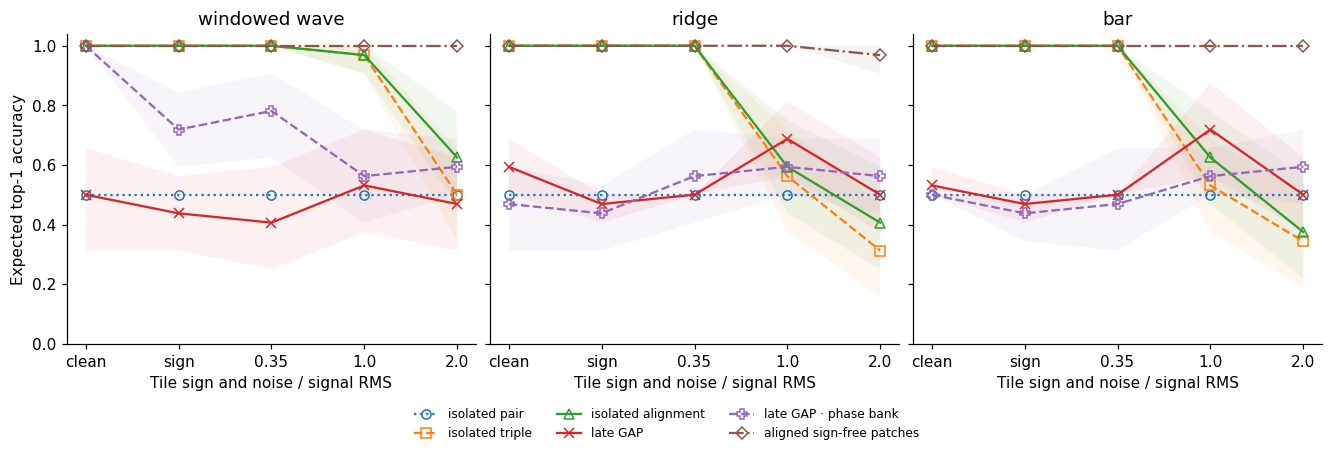

In [7]:
methods=['isolated pair','isolated triple','isolated alignment',
         'late GAP','late GAP · phase bank','aligned sign-free patches']
styles=['o:','s--','^-','x-','P--','D-.']
fig,axes=plt.subplots(1,3,figsize=(12,4),sharey=True)
for ax,family in zip(axes,FAMILIES):
    for method,style in zip(methods,styles):
        z=comparison[(comparison.motif==family)&(comparison.method==method)].set_index('condition').loc[list(CONDITIONS)]
        x=np.arange(len(z))
        ax.plot(x,z.top1,style,label=method,markerfacecolor='none')
        ax.fill_between(x,z.low95.to_numpy(),z.high95.to_numpy(),alpha=.065)
    ax.set(title=family,xticks=x,xticklabels=['clean','sign','0.35','1.0','2.0'],ylim=(0,1.04),
           xlabel='Tile sign and noise / signal RMS')
axes[0].set_ylabel('Expected top-1 accuracy')
fig.legend(*axes[-1].get_legend_handles_labels(),loc='outside lower center',ncol=3,fontsize=8,frameon=False)
show('18_frozen_retrieval')

## Uncertainty and interpretation
Intervals use 4,000 stratified resamples of 32 perturbation trajectories, preserving both prototype strata. The class label is arrangement modulo cyclic tile shifts. Motifs and perturbations are designed controls. Report empirical performance conditional on this gallery, architecture, checkpoint, input sizes and noise model. Equal retrieval results can come from very different levels of information loss. The algebraic patch-pooling ties, phase sweeps, and noise curves should be read together.

The next stage will choose any profile weights on separate development arrangement families and test on held-out families. These two prototypes serve as diagnostic cases.